# C. Discovered Links Analysis

This notebook analyses the enriched discovered-links dataset.

The purpose is to understand the structure of the discovered links data and identify which columns are useful for the next stage: candidate URL filtering and scoring.

## 1. Analytical Questions

- How many link observations and unique URLs do we have?
- Which source organisations contribute the most observations?
- Which source pages generate many link observations?
- What do `source_page_slug_en`, `full_url_slug_en`, `url_section_en`, and `link_text_en` tell us?
- Which columns are useful for candidate filtering and scoring?

## 2. Imports

In [105]:
import os
from pathlib import Path
from urllib.parse import urldefrag

os.environ.setdefault("MPLCONFIGDIR", str(Path("../.matplotlib-cache").resolve()))
os.environ.setdefault("MPL_IGNORE_SYSTEM_FONTS", "1")
Path(os.environ["MPLCONFIGDIR"]).mkdir(parents=True, exist_ok=True)

import matplotlib.pyplot as plt
import pandas as pd

## 3. Load Enriched Dataset

In [106]:
ENRICHED_DATA_PATH = Path("../data/interim/discovered_links_enriched.csv")

df = pd.read_csv(ENRICHED_DATA_PATH)

df.sample(10)


,source_organisation,source_page,source_page_slug,source_page_slug_en,depth,link_text,link_text_en,href,full_url,full_url_slug,full_url_slug_en,url_section,url_section_en
19576,nfk.nl,https://nfk.nl/aangesloten-organisaties,aangesloten-organisaties,affiliated organizations,1,Zeldzame kankers,Rare cancers,https://nfk.nl/themas/zeldzame-kankers,https://nfk.nl/themas/zeldzame-kankers,zeldzame-kankers,rare cancers,themas,themes
19490,nfk.nl,https://nfk.nl/themas/zeldzame-kankers,zeldzame-kankers,rare cancers,1,Manon van Splunter,Manon van Splunter,https://nfk.nl/organisatie/ons-team/manon-van-...,https://nfk.nl/organisatie/ons-team/manon-van-...,manon-van-splunter,manon-of-splunter,organisatie,organization
9012,iknl.nl,https://iknl.nl/nkr,nkr,nkr,1,Regiorapportages,Regional reports,/nkr/cijfers-op-maat/regiorapportages,https://iknl.nl/nkr/cijfers-op-maat/regiorappo...,regiorapportages,regional reports,nkr,nkr
3323,kanker.nl,https://www.kanker.nl/soorten-behandelingen/pr...,protonentherapie-protonenbestraling,proton therapy - proton radiation,1,Protonentherapie (protonenbestraling),Proton therapy (proton irradiation),/soorten-behandelingen/protonentherapie/algeme...,https://www.kanker.nl/soorten-behandelingen/pr...,protonentherapie-protonenbestraling,proton therapy - proton radiation,soorten-behandelingen,types of treatments
11176,iknl.nl,https://iknl.nl/kankersoorten/baarmoederhalska...,baarmoederhalskanker,cervical cancer,1,Databeschikbaarheid,Data availability,/themas/databeschikbaarheid,https://iknl.nl/themas/databeschikbaarheid,databeschikbaarheid,data availability,themas,themes
14031,zorgwijzer.nl,https://www.zorgwijzer.nl/zorgwijzers/kanker,kanker,canker,0,Over Zorgwijzer,About Zorgwijzer,https://www.zorgwijzer.nl/over-ons,https://www.zorgwijzer.nl/over-ons,over-ons,about us,over-ons,about us
7514,thuisarts.nl,https://www.thuisarts.nl/angst,angst,fear,1,Dwangstoornis,Compulsive disorder,/dwangstoornis,https://www.thuisarts.nl/dwangstoornis,dwangstoornis,compulsive disorder,dwangstoornis,compulsive disorder
20260,zorginstituutnederland.nl,https://www.zorginstituutnederland.nl/service/...,abonneren,subscribing,1,Sitemap,Sitemap,/sitemap,https://www.zorginstituutnederland.nl/sitemap,sitemap,sitemap,sitemap,sitemap
8869,iknl.nl,https://iknl.nl/webshop,webshop,webshop,1,Rapporten over dure geneesmiddelen,Reports on expensive medicines,/dure-geneesmiddelen/rapporten,https://iknl.nl/dure-geneesmiddelen/rapporten,rapporten,reports,dure-geneesmiddelen,expensive drugs
17603,nfk.nl,https://nfk.nl/inzichten,inzichten,insights,1,Werken bij NFK,Working at NFK,https://nfk.nl/organisatie/werken-bij-nfk,https://nfk.nl/organisatie/werken-bij-nfk,werken-bij-nfk,working at nfk,organisatie,organization


In [107]:
df.duplicated().sum()

np.int64(3158)

In [108]:
rows_before = len(df)

duplicate_rows = df.duplicated().sum()
print("exact duplicate rows:", duplicate_rows)

df = df.drop_duplicates().copy()

rows_after = len(df)

print("rows before:", rows_before)
print("rows after:", rows_after)
print("rows removed:", rows_before - rows_after)

exact duplicate rows: 3158
rows before: 20856
rows after: 17698
rows removed: 3158


Exact duplicate rows were removed before analysis because they represent repeated identical link observations and can inflate frequency-based EDA results. The raw dataset is preserved separately, while the analysis dataset uses a deduplicated working copy.

## 4. Helper Function

In [109]:
def plot_horizontal_counts(counts, title, x_label, y_label, figsize=(10, 7)):
    plt.figure(figsize=figsize)
    counts.sort_values().plot(kind="barh")
    plt.title(title)
    plt.xlabel(x_label)
    plt.ylabel(y_label)
    plt.tight_layout()
    plt.show()

## 5. Dataset Overview

In [110]:
overview_df = pd.DataFrame([
    # total link observations
    {"metric": "link_observations", "value": len(df)},
    # how many columns ?
    {"metric": "columns", "value": df.shape[1]},
    # how many unique urls?
    {"metric": "unique_full_urls", "value": df["full_url"].nunique()},
    # how many unique source page?
    {"metric": "unique_source_pages", "value": df["source_page"].nunique()},
    # how many source organisation (websites) crawled?
    {"metric": "source_organisations", "value": df["source_organisation"].nunique()},
    # what is the maximum depth reached during crawl ?
    {"metric": "max_depth", "value": df["depth"].max()},
])

overview_df

,metric,value
0,link_observations,17698
1,columns,13
2,unique_full_urls,3851
3,unique_source_pages,257
4,source_organisations,6
5,max_depth,2


### Observation

- Each row is a link observation, not necessarily a unique URL. The gap between link observations and unique URLs shows that the same destination URL can be discovered multiple times from different source pages.
- Investigating how frequently these URLs occur and how widely they are distributed across source pages could provide useful insights into their relative importance. It may also help determine whether frequently referenced URLs contain content that is particularly relevant to the community questions we aim to answer.

## 6. Source Organisation Analysis

In [111]:
# detailed overview of link disovery data set per organisation
source_organisation_summary_df = (
    df
    .groupby("source_organisation", dropna=False)
    .agg(
        link_observations=("full_url", "size"),
        unique_urls=("full_url", "nunique"),
        unique_source_pages=("source_page", "nunique"),
        max_depth=("depth", "max"),
    )
    .reset_index()
    .sort_values("link_observations", ascending=False)
)

source_organisation_summary_df

,source_organisation,link_observations,unique_urls,unique_source_pages,max_depth
0,iknl.nl,5690,502,39,1
1,kanker.nl,4477,1305,50,1
3,thuisarts.nl,3142,1318,50,1
2,nfk.nl,2333,210,40,1
5,zorgwijzer.nl,1128,292,39,2
4,zorginstituutnederland.nl,928,224,39,2


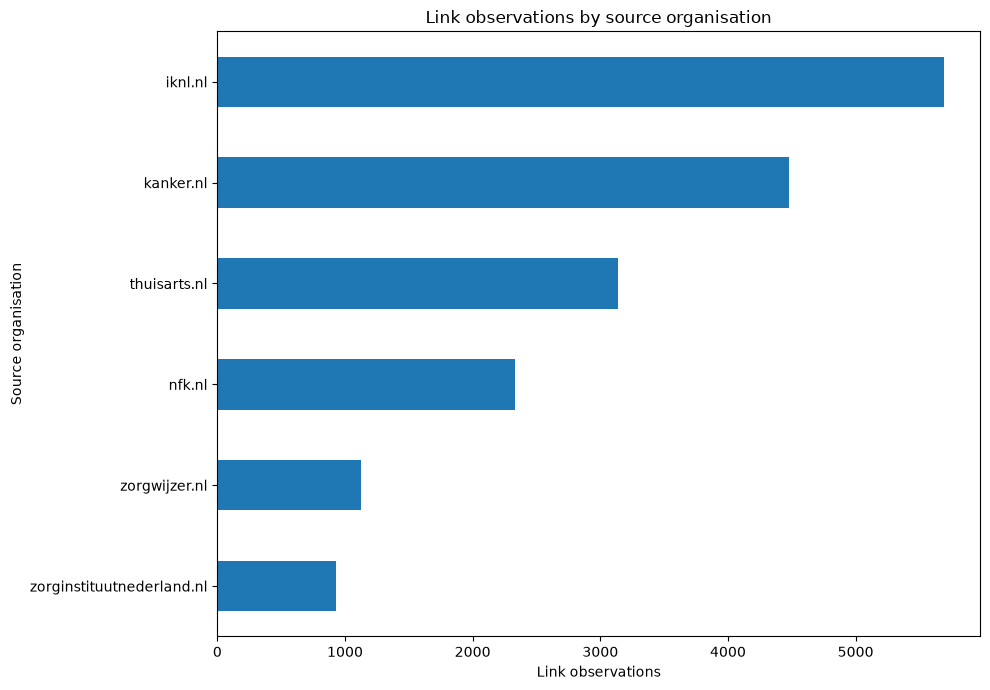

In [112]:
# horizontal bar chart of link observation count per organisation
counts = df["source_organisation"].value_counts()

plot_horizontal_counts(
    counts=counts,
    title="Link observations by source organisation",
    x_label="Link observations",
    y_label="Source organisation",
)

### Observation

- The crawl produced different link-observation patterns across source organisations. 
- `iknl.nl` and `nfk.nl` generated many link observations but relatively few unique URLs, suggesting repeated links or common navigation structures. 
- In contrast, `kanker.nl` and `thuisarts.nl` produced a larger number of unique URLs, indicating broader destination-page diversity. 
- This means the next filtering stage should not rely only on observation count; it should also consider unique URLs, source organisation, URL section, link text, and slug features.

## 7. Unique Value Analysis

In [113]:
unique_value_summary_df = pd.DataFrame([
    {"column": "source_page", "unique_values": df["source_page"].nunique()},
    {"column": "source_page_slug_en", "unique_values": df["source_page_slug_en"].nunique()},
    {"column": "full_url", "unique_values": df["full_url"].nunique()},
    {"column": "full_url_slug_en", "unique_values": df["full_url_slug_en"].nunique()},
    {"column": "url_section_en", "unique_values": df["url_section_en"].nunique()},
    {"column": "link_text_en", "unique_values": df["link_text_en"].nunique()},
])

unique_value_summary_df

,column,unique_values
0,source_page,257
1,source_page_slug_en,244
2,full_url,3851
3,full_url_slug_en,3237
4,url_section_en,857
5,link_text_en,4126


### Observation

The unique-value summary shows that slug columns improve readability but are not exact identifiers. There are 257 unique `source_page` values compared with 244 unique `source_page_slug_en` values, and 3,851 unique `full_url` values compared with 3,237 unique `full_url_slug_en` values. This means different pages can share the same slug.

Therefore, exact analysis should use `source_page` and `full_url`, while slug columns should be used as readable context features. `url_section_en` provides a useful mid-level website-area signal, and `link_text_en` is useful for keyword matching, although it may include varied wording and generic navigation labels.

## 8. Source Page Distribution

In [114]:
source_page_counts = (
    df
    .groupby(["source_page", "source_page_slug_en"], dropna=False)
    .size()
    .reset_index(name="link_observation_count")
    .sort_values("link_observation_count", ascending=False)
)

print("number of unique source pages:", df["source_page"].nunique())

source_page_counts.head(20)

number of unique source pages: 257


,source_page,source_page_slug_en,link_observation_count
174,https://www.thuisarts.nl/overzicht/onderwerpen#K,topics,723
173,https://www.thuisarts.nl/overzicht/onderwerpen,topics,723
175,https://www.thuisarts.nl/overzicht/videos,videos,258
81,https://www.kanker.nl/bibliotheek,library,172
92,https://www.kanker.nl/gevolgen-van-kanker/niet...,if-cure-is no longer possible,171
11,https://iknl.nl/kankersoorten/hemato-oncologie,hemato-oncology,171
105,https://www.kanker.nl/kankersoorten/borstkanke...,what-is breast cancer,170
24,https://iknl.nl/nkr,nkr,167
35,https://iknl.nl/nkr/uitleg-nkr-cijfers,explanation of nkr figures,166
25,https://iknl.nl/nkr/cijfers-op-maat,customized numbers,163


### Observation

- The highest link-observation counts come from source pages that appear to function as hub, index, or topic pages. For example, Thuisarts topic pages and video pages produce many outgoing links, while several IKNL NKR pages generate many repeated observations around cancer registry/statistics content.

- This suggests that high source-page frequency does not automatically mean high patient-navigation relevance. Some high-count pages may be useful hubs, while others may reflect website structure or specialist/statistical content. Therefore, source-page frequency should be used as a context signal, not as a relevance label by itself.

- The Thuisarts overview page appears twice because one version includes the `#K` anchor fragment. These URLs likely refer to the same underlying page, but are counted separately because `source_page` is stored as the exact URL string. This suggests that URL normalisation may be needed before exact source-page analysis or discovery frequency analysis.

- Some source pages may appear more than once because of URL variants such as anchor fragments. This can inflate source-page and slug-level observation counts. The issue is less serious when analysing unique destination URLs, but it should be considered before using discovery frequency as a scoring signal.


### Analyse source-page duplication from anchors and other defects

In [115]:
source_page_variant_test_df = df.assign(
    source_page_normalised=df["source_page"].apply(lambda url: urldefrag(str(url))[0]),
    full_url_normalised=df["full_url"].apply(lambda url: urldefrag(str(url))[0])
)

source_page_variant_test_df.head()

,source_organisation,source_page,source_page_slug,source_page_slug_en,depth,link_text,link_text_en,href,full_url,full_url_slug,full_url_slug_en,url_section,url_section_en,source_page_normalised,full_url_normalised
0,kanker.nl,https://www.kanker.nl/,homepage,homepage,0,We zijn er voor je. Kanker.nl,We are here for you. Kanker.nl,/,https://www.kanker.nl/,homepage,homepage,homepage,homepage,https://www.kanker.nl/,https://www.kanker.nl/
1,kanker.nl,https://www.kanker.nl/,homepage,homepage,0,Blogs,Blogs,/ervaringen-van-anderen/blogs,https://www.kanker.nl/ervaringen-van-anderen/b...,blogs,blogs,ervaringen-van-anderen,others' experiences,https://www.kanker.nl/,https://www.kanker.nl/ervaringen-van-anderen/b...
2,kanker.nl,https://www.kanker.nl/,homepage,homepage,0,In gesprek met elkaar,Talking to each other,/ervaringen-van-anderen/gespreksgroepen,https://www.kanker.nl/ervaringen-van-anderen/g...,gespreksgroepen,discussion groups,ervaringen-van-anderen,others' experiences,https://www.kanker.nl/,https://www.kanker.nl/ervaringen-van-anderen/g...
3,kanker.nl,https://www.kanker.nl/,homepage,homepage,0,Diagnose,Diagnosis,/diagnose,https://www.kanker.nl/diagnose,diagnose,diagnosis,diagnose,diagnosis,https://www.kanker.nl/,https://www.kanker.nl/diagnose
4,kanker.nl,https://www.kanker.nl/,homepage,homepage,0,Werk & kanker,Work & cancer,/werk,https://www.kanker.nl/werk,werk,work,werk,work,https://www.kanker.nl/,https://www.kanker.nl/werk


In [116]:
normalisation_summary = pd.DataFrame([
    {"metric": "unique_source_page_original", "value": df["source_page"].nunique()},
    {"metric": "unique_source_page_normalised", "value": source_page_variant_test_df["source_page_normalised"].nunique()},
    {"metric": "unique_full_url_original", "value": df["full_url"].nunique()},
    {"metric": "unique_full_url_normalised", "value": source_page_variant_test_df["full_url_normalised"].nunique()},
])

normalisation_summary

,metric,value
0,unique_source_page_original,257
1,unique_source_page_normalised,256
2,unique_full_url_original,3851
3,unique_full_url_normalised,3851


### Observation

- The test dataframe `source_page_variant_test_df` keeps the original `df` unchanged while adding normalised URL columns for this defect check.

- The number of unique `source_page` values decreases from 257 to 256 after removing anchor fragments, while the number of unique `full_url` values remains unchanged at 3,851.

- This indicates that anchor-based duplication occurs only for `https://www.thuisarts.nl/overzicht/onderwerpen` and its anchored variant, `https://www.thuisarts.nl/overzicht/onderwerpen#K`.

- The next step is to determine whether these two source-page variants produce exactly the same link observations and unique URL discoveries. If they do, a cleaned copy can drop the duplicate source-page variant without changing the raw `df`.


In [117]:
variant_pages = [
    "https://www.thuisarts.nl/overzicht/onderwerpen#K",
    "https://www.thuisarts.nl/overzicht/onderwerpen",
]

variant_check = (
    source_page_variant_test_df[source_page_variant_test_df["source_page"].isin(variant_pages)]
    .groupby("source_page")
    .agg(
        link_observations=("full_url", "size"),
        unique_full_urls=("full_url", "nunique"),
        unique_link_texts=("link_text", "nunique"),
    )
    .reset_index()
)

variant_check

,source_page,link_observations,unique_full_urls,unique_link_texts
0,https://www.thuisarts.nl/overzicht/onderwerpen,723,723,723
1,https://www.thuisarts.nl/overzicht/onderwerpen#K,723,723,723


In [118]:
page_with_anchor = "https://www.thuisarts.nl/overzicht/onderwerpen#K"
page_without_anchor = "https://www.thuisarts.nl/overzicht/onderwerpen"

urls_with_anchor = set(
    source_page_variant_test_df.loc[source_page_variant_test_df["source_page"] == page_with_anchor, "full_url"]
)

urls_without_anchor = set(
    source_page_variant_test_df.loc[source_page_variant_test_df["source_page"] == page_without_anchor, "full_url"]
)

print("same discovered full_url set:", urls_with_anchor == urls_without_anchor)
print("urls only in anchor version:", len(urls_with_anchor - urls_without_anchor))
print("urls only in clean version:", len(urls_without_anchor - urls_with_anchor))

same discovered full_url set: True
urls only in anchor version: 0
urls only in clean version: 0


In [119]:
source_page_anchor_variant = "https://www.thuisarts.nl/overzicht/onderwerpen#K"

df_without_source_page_anchor_variant = df.loc[
    df["source_page"] != source_page_anchor_variant
].copy()

drop_impact_summary = pd.DataFrame([
    {"metric": "rows_before", "value": len(df)},
    {"metric": "rows_to_drop", "value": int((df["source_page"] == source_page_anchor_variant).sum())},
    {"metric": "rows_after", "value": len(df_without_source_page_anchor_variant)},
    {"metric": "unique_source_pages_before", "value": df["source_page"].nunique()},
    {"metric": "unique_source_pages_after", "value": df_without_source_page_anchor_variant["source_page"].nunique()},
    {"metric": "unique_full_urls_before", "value": df["full_url"].nunique()},
    {"metric": "unique_full_urls_after", "value": df_without_source_page_anchor_variant["full_url"].nunique()},
])

df = df_without_source_page_anchor_variant.copy()
drop_impact_summary

,metric,value
0,rows_before,17698
1,rows_to_drop,723
2,rows_after,16975
3,unique_source_pages_before,257
4,unique_source_pages_after,256
5,unique_full_urls_before,3851
6,unique_full_urls_after,3851


### Observation and Notes

The `#K` anchor variant created duplicate source-page observations for the Thuisarts topics page. These rows are removed from the working `df` for the remaining source-page analysis so that the same page is not counted twice.

This cleanup can affect earlier summary values that were run before the reassignment, especially source-page frequency and any metrics based on link-observation counts. The analysis below continues with the cleaned dataframe.


### Source page distribution continues

In [120]:
# Count link observations per exact source page after removing the anchor duplicate.
# Keeping source_page_slug_en beside source_page makes the top pages easier to interpret.
source_page_counts = (
    df
    .groupby(["source_page", "source_page_slug_en"], dropna=False)
    .size()
    .reset_index(name="link_observation_count")
    .sort_values("link_observation_count", ascending=False)
)

print("number of unique source pages:", df["source_page"].nunique())

source_page_counts.head(20)


number of unique source pages: 256


,source_page,source_page_slug_en,link_observation_count
173,https://www.thuisarts.nl/overzicht/onderwerpen,topics,723
174,https://www.thuisarts.nl/overzicht/videos,videos,258
81,https://www.kanker.nl/bibliotheek,library,172
92,https://www.kanker.nl/gevolgen-van-kanker/niet...,if-cure-is no longer possible,171
11,https://iknl.nl/kankersoorten/hemato-oncologie,hemato-oncology,171
105,https://www.kanker.nl/kankersoorten/borstkanke...,what-is breast cancer,170
24,https://iknl.nl/nkr,nkr,167
35,https://iknl.nl/nkr/uitleg-nkr-cijfers,explanation of nkr figures,166
25,https://iknl.nl/nkr/cijfers-op-maat,customized numbers,163
28,https://iknl.nl/nkr/internationaal,internationally,160


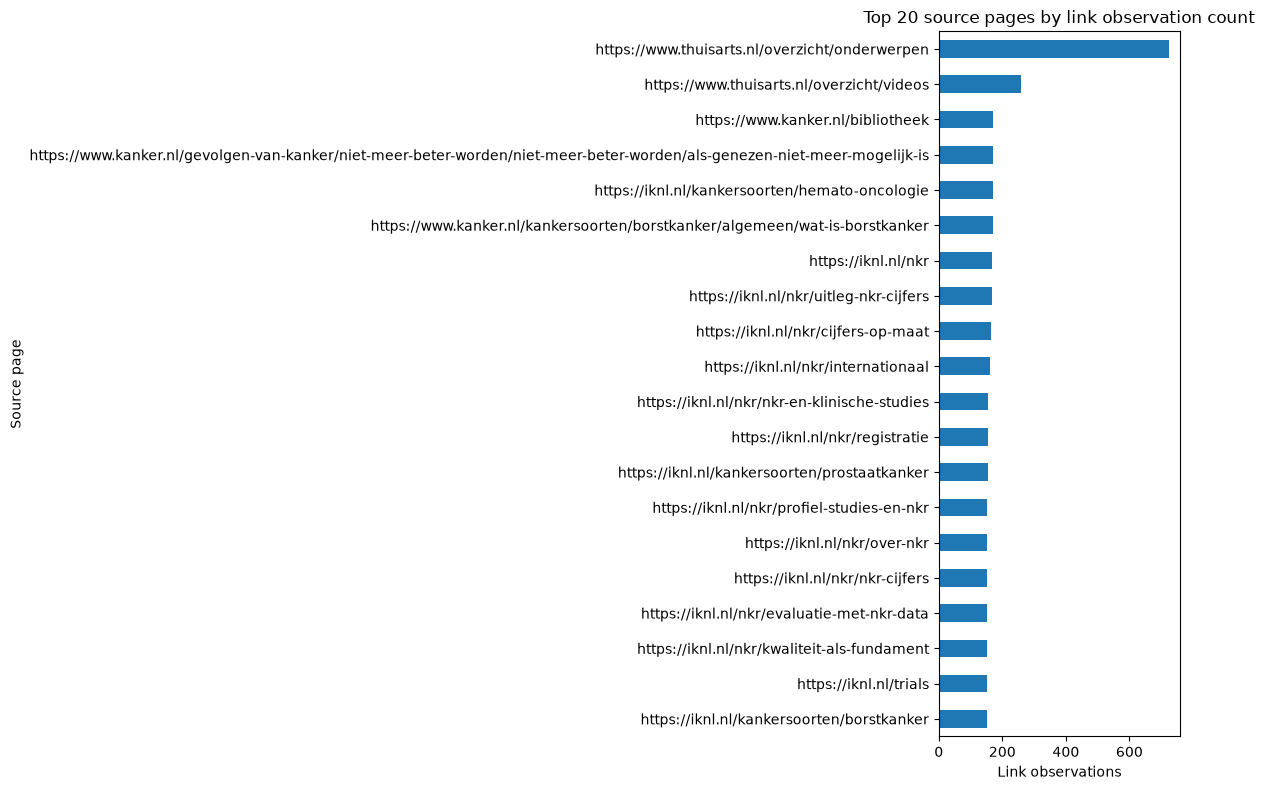

In [121]:
# The helper expects a Series, so index the top rows by source_page and plot only the count column.
top_source_page_counts = source_page_counts.head(20).set_index("source_page")["link_observation_count"]

plot_horizontal_counts(
    counts=top_source_page_counts,
    title="Top 20 source pages by link observation count",
    x_label="Link observations",
    y_label="Source page",
    figsize=(12, 8),
)


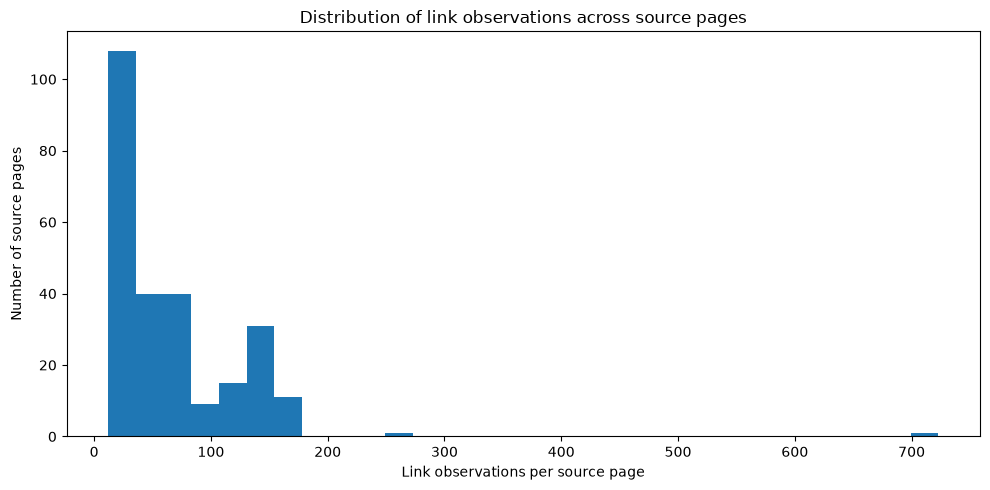

In [122]:
# Plot the distribution of counts across all source pages, not the full summary dataframe.
plt.figure(figsize=(10, 5))
source_page_counts["link_observation_count"].plot(kind="hist", bins=30)
plt.title("Distribution of link observations across source pages")
plt.xlabel("Link observations per source page")
plt.ylabel("Number of source pages")
plt.tight_layout()
plt.show()


### Observation

After removing the duplicated `#K` source-page variant, there are 256 unique source pages. The top source page is still `https://www.thuisarts.nl/overzicht/onderwerpen` with 731 link observations, followed by the Thuisarts videos overview and several Kanker.nl and IKNL hub or topic pages.

The histogram shows that source-page link observations are not evenly distributed. Most pages sit well below the largest hub page, while a smaller group of index, overview, cancer-type, or registry/statistics pages contributes many more links. This means source-page frequency is useful as a structural signal, but it should not be treated as relevance by itself.


## 9. Source Page Slug Analysis

In [123]:
# Count source-page slugs to see which readable page labels occur most often.
# A slug is easier to read than a full URL, but it can merge different pages with the same label.
source_page_slug_counts = df["source_page_slug_en"].value_counts()

print("number of unique source_page_slug_en:", df["source_page_slug_en"].nunique())
source_page_slug_counts.head(20)


number of unique source_page_slug_en: 244


source_page_slug_en
topics                           723
homepage                         427
videos                           258
types of cancer                  254
skin cancer                      219
projects                         194
tidings                          188
cervical cancer                  173
library                          172
if-cure-is no longer possible    171
hemato-oncology                  171
what-is breast cancer            170
nkr                              167
explanation of nkr figures       166
uterine cancer                   165
customized numbers               163
internationally                  160
pancreatic cancer                158
NKR and clinical studies         156
registration                     155
Name: count, dtype: int64

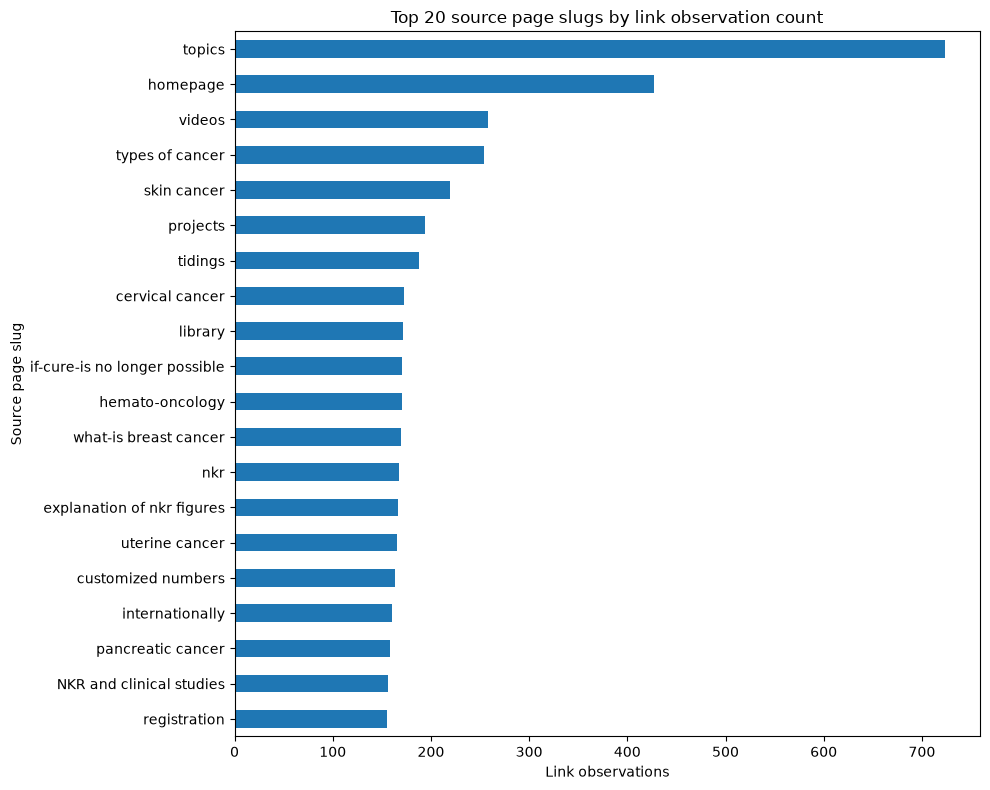

In [124]:
# Plot the most frequent slugs by link-observation count.
plot_horizontal_counts(
    counts=source_page_slug_counts.head(20),
    title="Top 20 source page slugs by link observation count",
    x_label="Link observations",
    y_label="Source page slug",
    figsize=(10, 8),
)


In [125]:
# Check whether a readable slug maps to one page or several pages/organisations.
# This prevents us from accidentally treating source_page_slug_en as a unique page identifier.
source_slug_uniqueness_df = (
    df
    .groupby("source_page_slug_en", dropna=False)
    .agg(
        link_observations=("source_page_slug_en", "size"),
        unique_source_pages=("source_page", "nunique"),
        source_organisations=("source_organisation", "nunique"),
    )
    .reset_index()
    .sort_values(["unique_source_pages", "link_observations"], ascending=False)
)

source_slug_uniqueness_df.head(20)


,source_page_slug_en,link_observations,unique_source_pages,source_organisations
116,homepage,427,5,5
200,types of cancer,254,2,2
185,skin cancer,219,2,2
170,projects,194,2,2
195,tidings,188,2,2
67,cervical cancer,173,2,2
204,uterine cancer,165,2,2
153,pancreatic cancer,158,2,2
142,organization,74,2,2
197,topics,723,1,1


### Observation

`source_page_slug_en` improves readability, but it is not a unique identifier. For example, `homepage` appears for 5 source pages across the 5 crawled organisations, which is expected because each website has its own homepage.

Several disease or content labels also appear across more than one source page or organisation, such as `types of cancer`, `skin cancer`, `cervical cancer`, and `uterine cancer`. These shared slugs are useful for thematic grouping, but exact page-level analysis should still use `source_page`, ideally together with `source_organisation`.

The slug plot is therefore best read as a high-level topic/page-label frequency view, while `source_slug_uniqueness_df` shows where those labels collapse multiple exact pages.


## 10. Full URL Slug Analysis

In [128]:
full_url_slug_counts = df["full_url_slug_en"].value_counts()

print("number of unique full_url_slug_en:", df["full_url_slug_en"].nunique())
full_url_slug_counts.head(20)

number of unique full_url_slug_en: 3237


full_url_slug_en
homepage                   384
tidings                    224
types of cancer            195
disclaimer                 128
contact                    127
contact address            118
research                    96
skin cancer                 94
consequences of cancer      92
about us                    92
guidelines                  89
care comparator             87
vind cancer help            85
themes                      83
palliative care             81
scientific publications     81
patient participation       81
projects                    80
about iknl                  80
contact-with-nfk            80
Name: count, dtype: int64

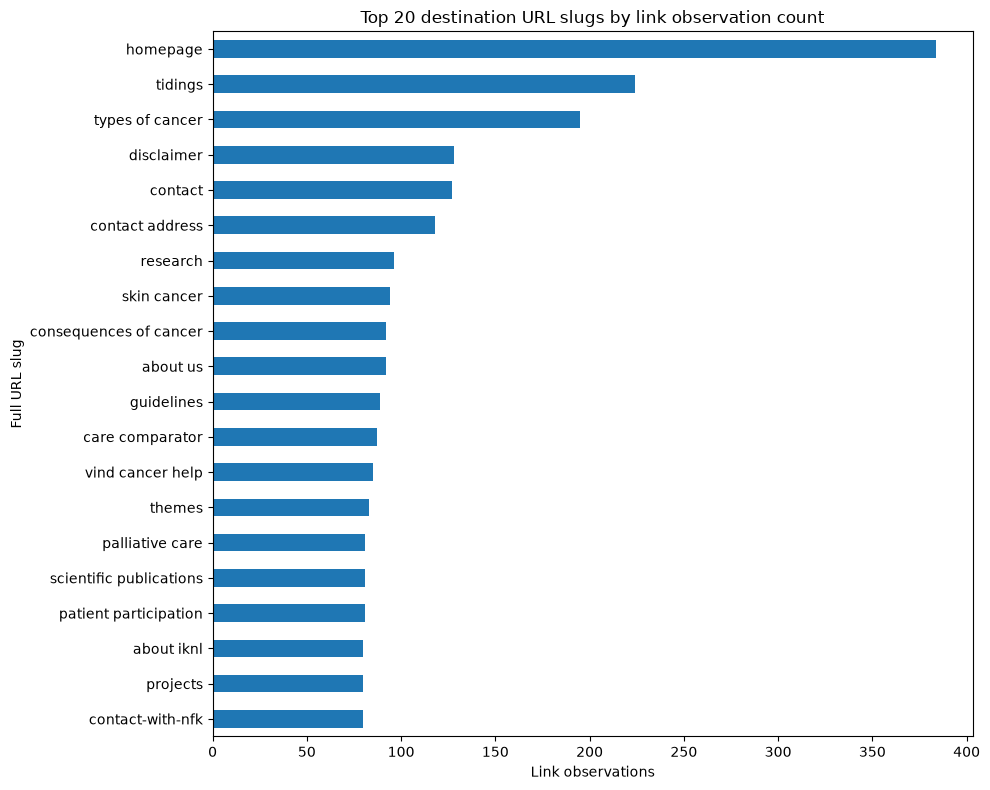

In [130]:
plot_horizontal_counts(
    counts=full_url_slug_counts.head(20),
    title="Top 20 destination URL slugs by link observation count",
    x_label="Link observations",
    y_label="Full URL slug",
    figsize=(10, 8),
)

In [131]:
full_url_slug_uniqueness_df = (
    df
    .groupby("full_url_slug_en", dropna=False)
    .agg(
        link_observations=("full_url_slug_en", "size"),
        unique_full_urls=("full_url", "nunique"),
        source_organisations=("source_organisation", "nunique"),
    )
    .reset_index()
    .sort_values(["unique_full_urls", "link_observations"], ascending=False)
)

full_url_slug_uniqueness_df.head(20)

,full_url_slug_en,link_observations,unique_full_urls,source_organisations
985,download,71,71,1
2861,tidings,224,22,3
2455,research,96,20,1
2369,public,38,19,1
2009,numerals,26,18,1
2908,treatment,18,18,1
2118,palliative phase,17,16,1
2941,trials,53,15,2
244,about the numbers,14,14,1
1654,life after cancer,15,13,1


### Observation

`full_url_slug_en` describes the destination page rather than the source page. This makes it especially useful for candidate URL filtering, because the next stage decides which destination URLs should be reviewed or scraped.

## 11. URL Section Analysis

In [132]:
url_section_counts = df["url_section_en"].value_counts()

print("number of unique url_section_en:", df["url_section_en"].nunique())
url_section_counts.head(25)

number of unique url_section_en: 857


url_section_en
types of cancer           3174
nkr                        825
themes                     765
about iknl                 580
overview                   547
cancer atlas               509
types of treatments        483
organization               455
cancer and life            429
help and support           400
consequences of cancer     398
palliative care            390
homepage                   384
service                    378
and                        351
others' experiences        341
insured care               306
remuneration               285
expensive drugs            242
insights                   220
our goals                  208
patient participation      204
topical                    197
about us                   196
tidings                    195
Name: count, dtype: int64

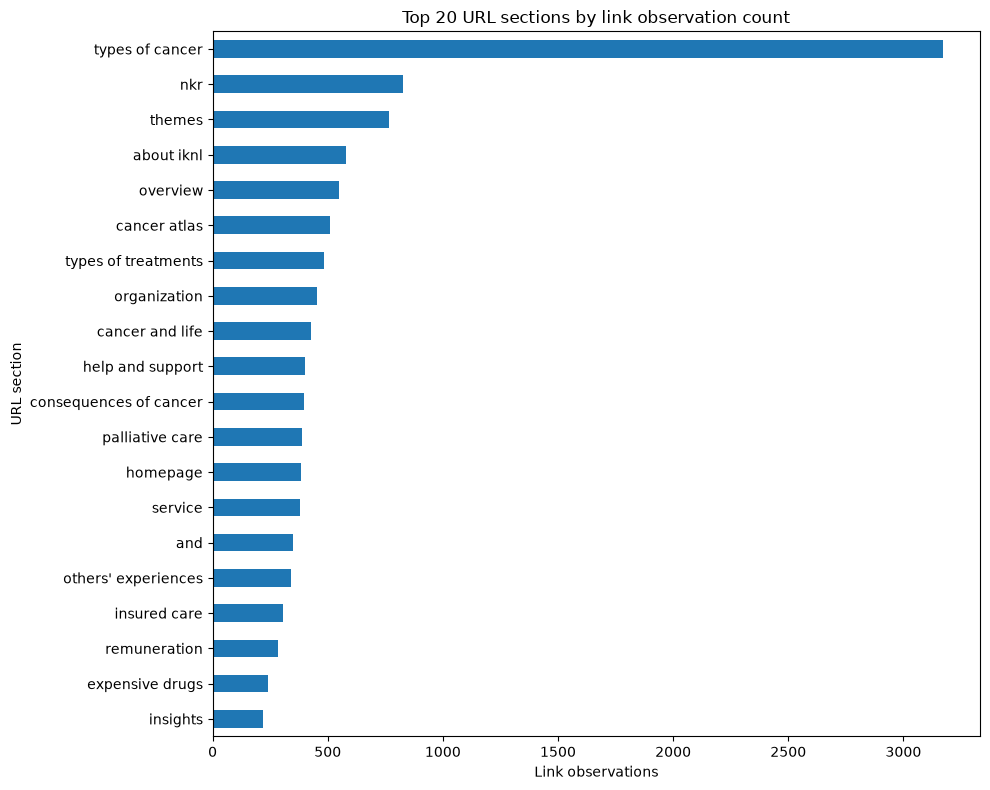

In [133]:
plot_horizontal_counts(
    counts=url_section_counts.head(20),
    title="Top 20 URL sections by link observation count",
    x_label="Link observations",
    y_label="URL section",
    figsize=(10, 8),
)

In [134]:
url_section_by_org_df = (
    df
    .groupby(["source_organisation", "url_section_en"], dropna=False)
    .agg(
        link_observations=("full_url", "size"),
        unique_urls=("full_url", "nunique"),
    )
    .reset_index()
    .sort_values("link_observations", ascending=False)
)

url_section_by_org_df.head(25)

,source_organisation,url_section_en,link_observations,unique_urls
83,kanker.nl,types of cancer,1822,717
41,iknl.nl,types of cancer,1352,222
28,iknl.nl,nkr,825,47
4,iknl.nl,about iknl,580,30
108,nfk.nl,themes,569,47
577,thuisarts.nl,overview,547,307
7,iknl.nl,cancer atlas,509,13
84,kanker.nl,types of treatments,483,126
99,nfk.nl,organization,455,26
6,iknl.nl,cancer and life,429,11


### Observation

`url_section_en` gives a high-level website area. It can help identify likely relevant sections, such as support or treatment areas, and possible noise sections, such as contact, news, jobs, privacy, or cookie pages.

## 12. Link Text Analysis

In [135]:
link_text_counts = df["link_text_en"].value_counts()

print("number of unique link_text_en:", df["link_text_en"].nunique())
link_text_counts.head(25)

number of unique link_text_en: 4126


link_text_en
News                       263
Contact                    167
Guidelines                 129
Privacy statement          128
Disclaimer                 127
read more                   99
Pancreatic cancer           94
Breast cancer               94
Lung cancer                 94
Prostate Cancer             94
Cervical cancer             93
Bladder cancer              93
Colon cancer                92
Skin cancer                 91
Scientific research         90
Accessibility               88
Projects                    80
Scientific publications     80
Organization                79
Contact & address           78
About IKNL                  78
Press                       78
Types of cancer             75
Home                        63
Appstore                    57
Name: count, dtype: int64

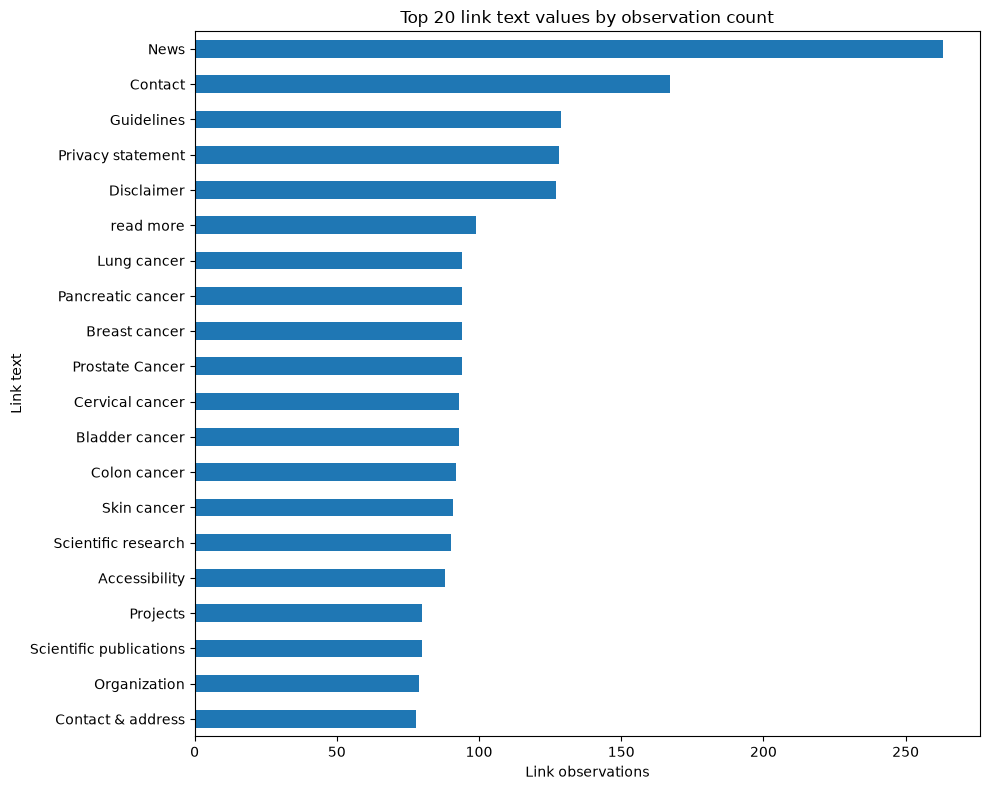

In [136]:
plot_horizontal_counts(
    counts=link_text_counts.head(20),
    title="Top 20 link text values by observation count",
    x_label="Link observations",
    y_label="Link text",
    figsize=(10, 8),
)

### Observation

`link_text_en` provides the visible label users see on the page. It is useful for filtering because relevant links often contain patient-navigation terms, while repeated generic labels may indicate menus, buttons, navigation links, or noise.

## 13. Duplicate URL Analysis

In [137]:
duplicate_url_summary_df = (
    df
    .groupby("full_url", dropna=False)
    .agg(
        discovery_count=("full_url", "size"),
        unique_source_pages=("source_page", "nunique"),
        source_organisations=("source_organisation", "nunique"),
        full_url_slug_en=("full_url_slug_en", "first"),
        link_text_examples=("link_text_en", lambda values: "; ".join(list(dict.fromkeys(values.dropna().astype(str)))[:5])),
    )
    .reset_index()
    .sort_values(["source_organisations", "unique_source_pages", "discovery_count"], ascending=False)
)

duplicate_url_summary_df.head(25)

,full_url,discovery_count,unique_source_pages,source_organisations,full_url_slug_en,link_text_examples
1118,https://www.kanker.nl/kankersoorten,117,50,1,types of cancer,See all cancers (A-Z); More types of cancer; T...
1056,https://www.kanker.nl/hulp-en-ondersteuning/st...,72,50,1,ask a professional your question,Ask a pro; professionals; Ask a pro Ask an exp...
1031,https://www.kanker.nl/hulp-en-ondersteuning/ap...,68,50,1,appstore,Appstore; Image Appstore Title Work independen...
1053,https://www.kanker.nl/hulp-en-ondersteuning/de...,59,50,1,the-kankernl-info line,Infoline; Educators of the kanker.nl info line...
823,https://www.kanker.nl/ervaringen-van-anderen/l...,56,50,1,peer finder,Peer finder; Image Peer Contact Title Peer Fin...
1855,https://www.kanker.nl/soorten-behandelingen,55,50,1,types of treatments,More treatments...; Types of treatments
733,https://www.kanker.nl/ervaringen-van-anderen/b...,54,50,1,blogs,Blogs; Blogs Read blogs; Blogs Read other peop...
699,https://www.kanker.nl/agenda,53,50,1,planner,Activity calendar; Check out the agenda; Image...
860,https://www.kanker.nl/gevolgen-van-kanker,53,50,1,consequences of cancer,See more consequences of cancer; Consequences ...
1114,https://www.kanker.nl/ipso,53,50,1,ipso,IPSO centers; Image Organizations Title Center...


### Observation

URLs discovered many times may be important hub pages, repeated navigation links, or common support resources. Discovery frequency can become one signal in candidate URL scoring, but it should not be used alone.

## 14. Summary: Useful Columns For Next Stage

Useful columns for candidate filtering and scoring:

- `full_url`: exact destination URL and the main unit for deduplication.
- `source_organisation`: helps preserve source trust and compare coverage.
- `source_page`: exact page where a link was discovered.
- `source_page_slug_en`: readable source-page context, but not unique.
- `full_url_slug_en`: readable destination-page topic and likely useful for filtering.
- `url_section_en`: high-level website area that can reveal useful sections or noise sections.
- `link_text_en`: visible link label and strong keyword-matching signal.
- `depth`: crawl-depth metadata that may help identify broad navigation pages versus deeper content.

Next notebook should use these columns to create candidate URL filtering and scoring rules.